### Part 3: Recruitment and Hiring Funnel Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\vssag\Desktop\Task 3.csv")

### Understanding the data setUnderstanding the data set

In [3]:
df.sample(5) # It will give random 5 rows.

,Candidate ID,Job Role,Application Date,Screening Status,Interview Score,Interview Status,Offer Status,Joining Status,Recruitment Source,Joining Date
1778,CAND-01782,Software Engineer,2023-05-01,Passed,4.0,Rejected,Not Offered,Not Joined,Indeed,NaN
2334,CAND-02339,Project Manager,2025-10-15,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Company Website,NaN
2133,CAND-02137,Software Engineer,2025-11-12,Passed,NaN,Not Scheduled,Not Offered,Not Joined,Employee Referral,NaN
1979,CAND-01983,Marketing Specialist,2025-09-28,Passed,NaN,Not Scheduled,Not Offered,Not Joined,Naukri,NaN
1484,CAND-01487,Sales Executive,2023-04-03,Passed,7.2,Selected,Accepted,Joined,Indeed,2023-05-27


In [4]:
df.head() # It shows top five rows

,Candidate ID,Job Role,Application Date,Screening Status,Interview Score,Interview Status,Offer Status,Joining Status,Recruitment Source,Joining Date
0,CAND-00001,Sales Executive,2024-08-21,Passed,6.2,Selected,Accepted,Joined,Employee Referral,2024-09-09
1,CAND-00002,Customer Support,2024-07-04,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Naukri,NaN
2,CAND-00003,Software Engineer,2025-04-22,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Naukri,NaN
3,CAND-00004,Software Engineer,2023-01-09,Passed,5.8,Selected,Accepted,Joined,Employee Referral,2023-02-12
4,CAND-00005,Software Engineer,2023-09-21,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Recruitment Agency,NaN


In [5]:
df.head() # It shows top five rows

,Candidate ID,Job Role,Application Date,Screening Status,Interview Score,Interview Status,Offer Status,Joining Status,Recruitment Source,Joining Date
0,CAND-00001,Sales Executive,2024-08-21,Passed,6.2,Selected,Accepted,Joined,Employee Referral,2024-09-09
1,CAND-00002,Customer Support,2024-07-04,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Naukri,NaN
2,CAND-00003,Software Engineer,2025-04-22,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Naukri,NaN
3,CAND-00004,Software Engineer,2023-01-09,Passed,5.8,Selected,Accepted,Joined,Employee Referral,2023-02-12
4,CAND-00005,Software Engineer,2023-09-21,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Recruitment Agency,NaN


In [6]:
df.tail() # It shows top last rows

,Candidate ID,Job Role,Application Date,Screening Status,Interview Score,Interview Status,Offer Status,Joining Status,Recruitment Source,Joining Date
2925,CAND-00552,Project Manager,2023-11-21,Passed,5.0,Pending,Not Offered,Not Joined,LinkedIn,NaN
2926,CAND-02784,Finance Analyst,2024-02-16,Passed,7.5,Selected,Accepted,Joined,Naukri,2024-05-06
2927,CAND-01894,HR Executive,2025-07-23,Passed,NaN,Not Scheduled,Not Offered,Not Joined,LinkedIn,NaN
2928,CAND-00934,Data Analyst,2023-04-21,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,Company Website,NaN
2929,CAND-02540,Customer Support,2023-04-04,Rejected,NaN,Not Scheduled,Not Offered,Not Joined,LinkedIn,NaN


In [7]:
print(df.columns.tolist()) # It shows All column names in a list.

['Candidate ID', 'Job Role', 'Application Date', 'Screening Status', 'Interview Score', 'Interview Status', 'Offer Status', 'Joining Status', 'Recruitment Source', 'Joining Date']


In [8]:
df.info() # It will give Dataset structure. 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Candidate ID        2930 non-null   object 
 1   Job Role            2926 non-null   object 
 2   Application Date    2930 non-null   object 
 3   Screening Status    2930 non-null   object 
 4   Interview Score     1793 non-null   float64
 5   Interview Status    2930 non-null   object 
 6   Offer Status        2930 non-null   object 
 7   Joining Status      2930 non-null   object 
 8   Recruitment Source  2925 non-null   object 
 9   Joining Date        632 non-null    object 
dtypes: float64(1), object(9)
memory usage: 229.0+ KB


In [9]:
df.describe() # It shows statistical summary of the dataset

,Interview Score
count,1793.000000
mean,6.479922
std,1.532807
min,0.000000
25%,5.400000
50%,6.500000
75%,7.600000
max,11.000000


In [10]:
df.isnull().any() # Check any missing value in dataset by each column.

Candidate ID          False
Job Role               True
Application Date      False
Screening Status      False
Interview Score        True
Interview Status      False
Offer Status          False
Joining Status        False
Recruitment Source     True
Joining Date           True
dtype: bool

In [11]:
df.isnull().sum() # It shows all misiing not/nll in each column.

Candidate ID             0
Job Role                 4
Application Date         0
Screening Status         0
Interview Score       1137
Interview Status         0
Offer Status             0
Joining Status           0
Recruitment Source       5
Joining Date          2298
dtype: int64

### 1. Clean candidate records and standardize recruitment stage labels.

In [12]:
df["Job Role"].unique()  # Check unique values in job role column

array(['Sales Executive', 'Customer Support', 'Software Engineer',
       'Marketing Specialist', 'HR Executive', 'Project Manager',
       'Finance Analyst', 'Data Analyst', nan], dtype=object)

In [13]:
df["Screening Status"].unique()  # Check unique values in screening status colum

array(['Passed', 'Rejected', 'Pending', 'passed'], dtype=object)

In [14]:
df["Interview Status"].unique()  # Check unique values in interview status column

array(['Selected', 'Not Scheduled', 'Rejected', 'Pending',
       'NOT SCHEDULED', 'PENDING', 'REJECTED'], dtype=object)

In [15]:
df["Offer Status"].unique()  # Check unique values in offer status column

array(['Accepted', 'Not Offered', 'Pending', 'Declined', 'Not Offered '],
      dtype=object)

In [16]:
df["Joining Status"].unique()  # Check unique values in joining status column

array(['Joined', 'Not Joined', 'Withdrawn', 'Pending', 'not joined'],
      dtype=object)

In [17]:
df["Recruitment Source"].unique()  # Check unique values in recruitment source column

array(['Employee Referral', 'Naukri', 'Recruitment Agency',
       'Campus Recruitment', 'Indeed', 'LinkedIn', 'Company Website',
       ' indeed ', nan, ' recruitment agency ', ' employee referral ',
       ' company website ', ' campus recruitment '], dtype=object)

In [18]:
df["Job Role"].unique()  # Check unique values in job role column

array(['Sales Executive', 'Customer Support', 'Software Engineer',
       'Marketing Specialist', 'HR Executive', 'Project Manager',
       'Finance Analyst', 'Data Analyst', nan], dtype=object)

In [19]:
df["Job Role"] = df["Job Role"].str.strip().str.title()  # Correct inconsistent job role names

In [20]:
df["Job Role"].unique()  # Check unique values again

array(['Sales Executive', 'Customer Support', 'Software Engineer',
       'Marketing Specialist', 'Hr Executive', 'Project Manager',
       'Finance Analyst', 'Data Analyst', nan], dtype=object)

In [21]:
df["Screening Status"].unique()  # Check unique values in screening status column

array(['Passed', 'Rejected', 'Pending', 'passed'], dtype=object)

In [22]:
df["Screening Status"] = df["Screening Status"].str.strip().str.title()  # Correct inconsistent values

In [23]:
df["Screening Status"].unique()  # Check unique values again

array(['Passed', 'Rejected', 'Pending'], dtype=object)

In [24]:
df["Interview Status"].unique()  # Check unique values in interview status column

array(['Selected', 'Not Scheduled', 'Rejected', 'Pending',
       'NOT SCHEDULED', 'PENDING', 'REJECTED'], dtype=object)

In [25]:
df["Interview Status"] = df["Interview Status"].str.strip().str.title()  # Correct inconsistent values

In [26]:
df["Interview Status"].unique()  # Check unique values again

array(['Selected', 'Not Scheduled', 'Rejected', 'Pending'], dtype=object)

In [27]:
df["Offer Status"].unique()  # Check unique values in offer status column

array(['Accepted', 'Not Offered', 'Pending', 'Declined', 'Not Offered '],
      dtype=object)

In [28]:
df["Offer Status"] = df["Offer Status"].str.strip().str.title()  # Correct inconsistent values

In [29]:
df["Offer Status"].unique()  # Check unique values again

array(['Accepted', 'Not Offered', 'Pending', 'Declined'], dtype=object)

In [30]:
df["Joining Status"].unique()  # Check unique values in joining status column

array(['Joined', 'Not Joined', 'Withdrawn', 'Pending', 'not joined'],
      dtype=object)

In [31]:
df["Joining Status"] = df["Joining Status"].str.strip().str.title()  # Correct inconsistent values

In [32]:
df["Joining Status"].unique()  # Check unique values again

array(['Joined', 'Not Joined', 'Withdrawn', 'Pending'], dtype=object)

In [33]:
df["Recruitment Source"].unique()  # Check unique values in recruitment source column

array(['Employee Referral', 'Naukri', 'Recruitment Agency',
       'Campus Recruitment', 'Indeed', 'LinkedIn', 'Company Website',
       ' indeed ', nan, ' recruitment agency ', ' employee referral ',
       ' company website ', ' campus recruitment '], dtype=object)

In [34]:
df["Recruitment Source"] = df["Recruitment Source"].str.strip().str.title()  # Correct inconsistent values

In [35]:
df["Recruitment Source"].unique()  # Check unique values again

array(['Employee Referral', 'Naukri', 'Recruitment Agency',
       'Campus Recruitment', 'Indeed', 'Linkedin', 'Company Website', nan],
      dtype=object)

In [36]:
df.isnull().sum()  # Check missing values in all columns

Candidate ID             0
Job Role                 4
Application Date         0
Screening Status         0
Interview Score       1137
Interview Status         0
Offer Status             0
Joining Status           0
Recruitment Source       5
Joining Date          2298
dtype: int64

In [37]:
df["Screening Status"].isna().sum()

np.int64(0)

In [38]:
df["Screening Status"].value_counts()  # Check category distribution

Screening Status
Passed      2056
Rejected     793
Pending       81
Name: count, dtype: int64

In [39]:
df["Screening Status"] = df["Screening Status"].fillna(df["Screening Status"].mode()[0])  # Fill missing values with mode

In [40]:
df["Screening Status"].isna().sum()

np.int64(0)

In [41]:
df["Interview Status"].value_counts() # Check category distribution

Interview Status
Selected         1151
Not Scheduled    1117
Rejected          595
Pending            67
Name: count, dtype: int64

In [42]:
df["Interview Status"] = df["Interview Status"].fillna(df["Interview Status"].mode()[0])  # Fill missing values with mode

In [43]:
df["Screening Status"].isna().sum() # Check values agaian.

np.int64(0)

In [44]:
df["Offer Status"].value_counts()  # Check category distribution

Offer Status
Not Offered    2006
Accepted        708
Declined        175
Pending          41
Name: count, dtype: int64

In [45]:
df["Offer Status"] = df["Offer Status"].fillna("Unknown")  # Fill missing values with mode

In [46]:
df["Offer Status"].isna().sum()  # Check missing values

np.int64(0)

In [47]:
df["Offer Status"].value_counts()  # Check category distribution

Offer Status
Not Offered    2006
Accepted        708
Declined        175
Pending          41
Name: count, dtype: int64

In [48]:
df["Joining Status"] = df["Joining Status"].fillna("Unknown")  # Fill missing values with Unknown

In [49]:
df["Joining Status"].isna().sum()  # Check missing values

np.int64(0)

In [50]:
df["Recruitment Source"].value_counts()  # Check category distribution

Recruitment Source
Linkedin              711
Naukri                658
Employee Referral     439
Indeed                360
Company Website       329
Campus Recruitment    248
Recruitment Agency    180
Name: count, dtype: int64

In [51]:
df["Recruitment Source"] = df["Recruitment Source"].fillna(df["Recruitment Source"].mode())  # Fill only missing values

In [52]:
df["Recruitment Source"].isna().sum()  # Check missing values

np.int64(5)

In [53]:
df["Recruitment Source"].value_counts()  # Check category distribution

Recruitment Source
Linkedin              711
Naukri                658
Employee Referral     439
Indeed                360
Company Website       329
Campus Recruitment    248
Recruitment Agency    180
Name: count, dtype: int64

In [54]:
df["Interview Score"].describe()  # Check statistical summary

count    1793.000000
mean        6.479922
std         1.532807
min         0.000000
25%         5.400000
50%         6.500000
75%         7.600000
max        11.000000
Name: Interview Score, dtype: float64

In [55]:
df["Interview Score"].nunique()  # Check number of unique scores

86

In [56]:
df["Interview Score"].value_counts().sort_index()  # Check score frequency

Interview Score
0.0      2
1.3      1
1.5      1
1.7      1
1.8      1
        ..
9.7      8
9.8      4
9.9      3
10.0    15
11.0     2
Name: count, Length: 86, dtype: int64

In [57]:
df["Interview Score"].median()  # Check median score

6.5

In [58]:
df["Interview Score"] = df["Interview Score"].fillna(df["Interview Score"].median()) # Fill not/null with median.

In [59]:
df["Application Date"].isna().sum()  # Check missing dates

np.int64(0)

In [60]:
df.duplicated().sum()  # Check duplicate records

np.int64(6)

In [61]:
df = df.drop_duplicates() # Removed Duplicates records.

In [62]:
df.duplicated().sum()  # Check duplicate records

np.int64(0)

### 2. Calculate the number of candidates at each recruitment stage

In [63]:
df["Joining Status"].value_counts() # Check joining status distribution


Joining Status
Not Joined    2217
Joined         631
Pending         47
Withdrawn       29
Name: count, dtype: int64

### 3. Calculate screening, interview, offer acceptance, and joining conversion rates

In [64]:
total_applicant=df["Screening Status"].value_counts() # Count total applicants
print(total_applicant)

total_applicant=df["Screening Status"].value_counts().sum() # Count passed applicants
print(total_applicant)

passed_applicant = df["Screening Status"].value_counts()["Passed"] # Calculate screening conversion rate
print(passed_applicant)

Screening Status
Passed      2053
Rejected     790
Pending       81
Name: count, dtype: int64
2924
2053


In [65]:
passed_rate = (passed_applicant/total_applicant)*100  # Display conversion rate
print(passed_rate)

70.21203830369357


In [66]:
total_interview = df["Interview Status"].value_counts() # Count interview status
print(total_interview)

total_interview = df["Interview Status"].value_counts().sum() # Count total candidates
print(total_interview)

passed_interview = df["Interview Status"].value_counts()["Selected"] # Count selected candidates
print(passed_interview)

Interview Status
Selected         1150
Not Scheduled    1113
Rejected          595
Pending            66
Name: count, dtype: int64
2924
1150


In [67]:
selected_rate = passed_interview/total_interview*100 # Calculate interview conversion rate
print(selected_rate)

39.3296853625171


In [68]:
offer_total = df["Offer Status"].value_counts() # Count offer status
print(offer_total)

offer_total = df["Offer Status"].value_counts().sum() # Count total offers
print(offer_total)

offer_accepted = df["Offer Status"].value_counts()["Accepted"] # Count accepted offers
print(offer_accepted)

Offer Status
Not Offered    2001
Accepted        707
Declined        175
Pending          41
Name: count, dtype: int64
2924
707


In [69]:
offer_rate = offer_accepted/offer_total*100 # Calculate offer acceptance rate
print(offer_rate)

24.17920656634747


In [70]:
joining_total = df["Joining Status"].value_counts() # Count joining status
print(joining_total)

joining_total = df["Joining Status"].value_counts().sum() # Count total candidates
print(joining_total)

joining_joined = df["Joining Status"].value_counts()["Joined"] # Count joined candidates
print(joining_joined)

Joining Status
Not Joined    2217
Joined         631
Pending         47
Withdrawn       29
Name: count, dtype: int64
2924
631


In [71]:
joining_rate = joining_joined/joining_total*100 # Calculate joining conversion rate
print(joining_rate)

21.58002735978112


In [72]:
df.dtypes 

Candidate ID           object
Job Role               object
Application Date       object
Screening Status       object
Interview Score       float64
Interview Status       object
Offer Status           object
Joining Status         object
Recruitment Source     object
Joining Date           object
dtype: object

### 4. Compare recruitment sources based on candidate conversion rates

In [73]:
Recruitment_total = df["Recruitment Source"].value_counts() # Count candidates from each recruitment source
print(Recruitment_total)  

Recruitment Source
Linkedin              708
Naukri                657
Employee Referral     438
Indeed                360
Company Website       328
Campus Recruitment    248
Recruitment Agency    180
Name: count, dtype: int64


In [74]:
screening_total = df["Recruitment Source"].value_counts() # Count total candidates by recruitment source
print(screening_total)

print("PASSED CANDIDATES :")

screening_passed = df[df["Screening Status"] == "Passed"]["Recruitment Source"].value_counts()
print(screening_passed) # Count passed candidates for each recruitment source


Recruitment Source
Linkedin              708
Naukri                657
Employee Referral     438
Indeed                360
Company Website       328
Campus Recruitment    248
Recruitment Agency    180
Name: count, dtype: int64
PASSED CANDIDATES :
Recruitment Source
Linkedin              503
Naukri                442
Employee Referral     368
Indeed                237
Company Website       216
Campus Recruitment    154
Recruitment Agency    129
Name: count, dtype: int64


In [75]:
conversation_rate  = screening_passed/screening_total*100 # Calculate conversion rate for each recruitment source
print(conversation_rate)

Recruitment Source
Linkedin              71.045198
Naukri                67.275495
Employee Referral     84.018265
Indeed                65.833333
Company Website       65.853659
Campus Recruitment    62.096774
Recruitment Agency    71.666667
Name: count, dtype: float64


In [76]:
df.dtypes # Check data types of all columns

Candidate ID           object
Job Role               object
Application Date       object
Screening Status       object
Interview Score       float64
Interview Status       object
Offer Status           object
Joining Status         object
Recruitment Source     object
Joining Date           object
dtype: object

In [77]:
df["Application Date"] = pd.to_datetime(df["Application Date"]) # Convert application date to datetime
df["Joining Date"] = pd.to_datetime(df["Joining Date"]) # Convert joining date to datetime

df["Hiring Time"] = (df["Joining Date"] - df["Application Date"]).dt.days  # Calculate hiring time in days

df[df["Joining Status"] == "Joined"]["Hiring Time"].mean()  ## Calculate average hiring time for joined candidates

np.float64(34.74484944532488)

### 6. Show candidate counts at each recruitment stage

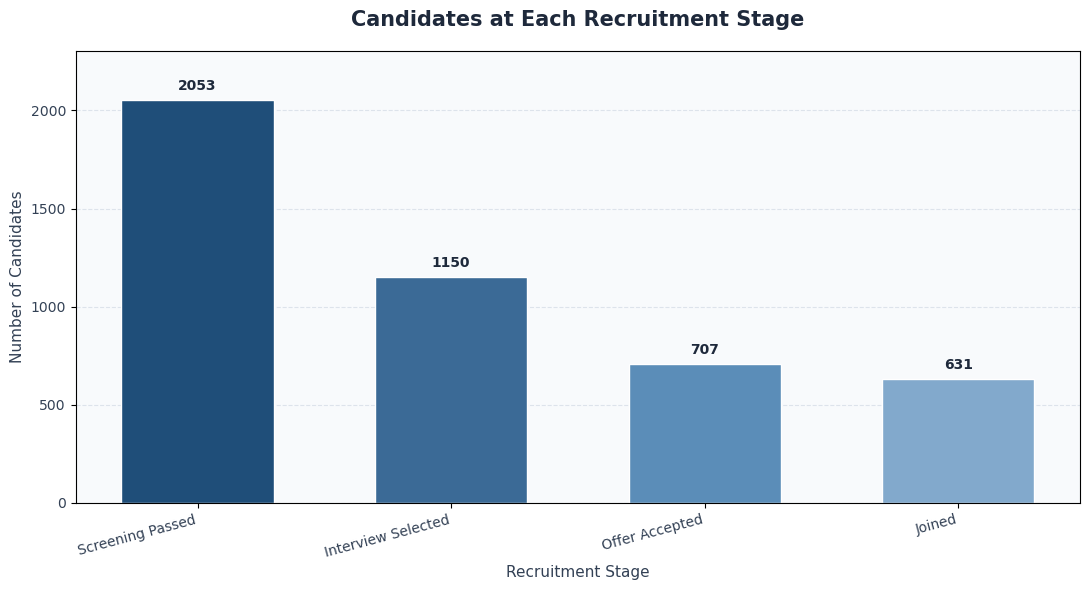

In [84]:
plt.figure(figsize=(11, 6), facecolor="#FFFFFF")
plt.gca().set_facecolor("#F8FAFC")

colors = ["#1F4E79", "#3B6A96", "#5B8DB8", "#82A9CC"]

bars = plt.bar(
    stages, counts,
    color=colors,
    edgecolor="#FFFFFF",
    linewidth=1,
    width=0.6
)

plt.ylim(0, max(counts) + 250)

plt.title("Candidates at Each Recruitment Stage",
          fontsize=15, fontweight="bold", color="#1E293B", pad=18)

plt.xlabel("Recruitment Stage", fontsize=11, color="#334155")
plt.ylabel("Number of Candidates", fontsize=11, color="#334155")

plt.xticks(rotation=15, ha="right", color="#334155")
plt.yticks(color="#334155")

plt.bar_label(bars, padding=5, fontsize=10,
              fontweight="bold", color="#1E293B")

plt.grid(axis="y", linestyle="--", color="#CBD5E1", alpha=0.6)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

### 7. Compare recruitment source conversion rates

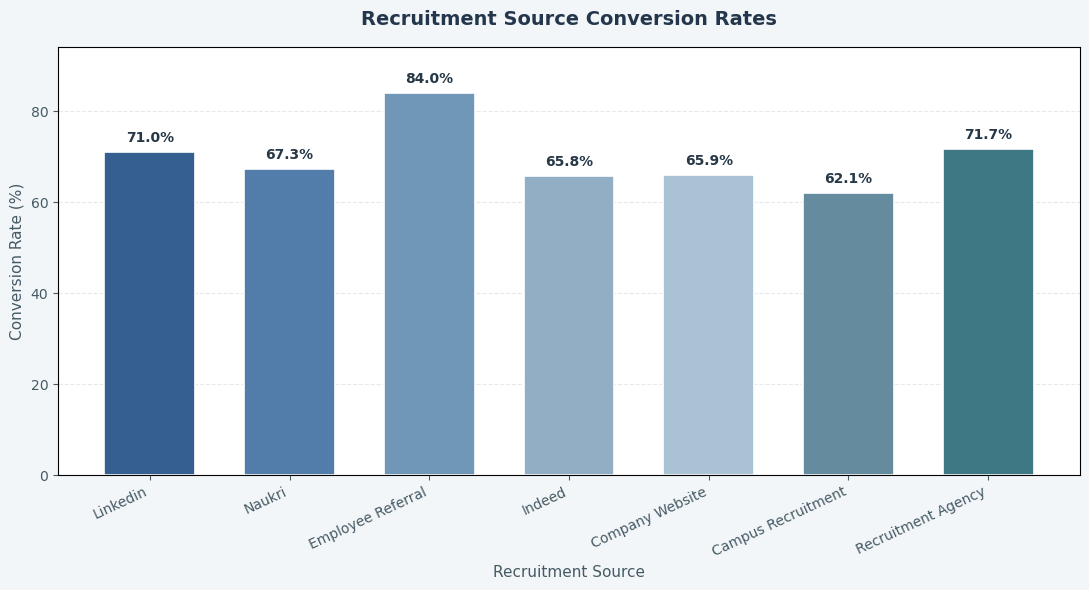

In [89]:
colors = ["#365F91", "#527DAA", "#7097B8", "#91AEC5",
          "#A9C2D4", "#648C9E", "#3F7885", "#789B9B"]

fig, ax = plt.subplots(figsize=(11, 6), facecolor="#F3F6F9")
ax.set_facecolor("#FFFFFF")

bars = ax.bar(
    name, values,
    color=colors[:len(name)],
    edgecolor="#FFFFFF",
    linewidth=1.2,
    width=0.65
)

ax.set_title("Recruitment Source Conversion Rates",
             fontsize=14, fontweight="bold", color="#24364B", pad=16)

ax.set_xlabel("Recruitment Source", fontsize=11, color="#455A64")
ax.set_ylabel("Conversion Rate (%)", fontsize=11, color="#455A64")

ax.tick_params(axis="both", colors="#455A64")
plt.xticks(rotation=25, ha="right")

ax.set_ylim(0, max(values) + 10)

ax.bar_label(bars, fmt="%.1f%%", padding=5,
             fontsize=10, fontweight="bold", color="#263746")

ax.grid(axis="y", linestyle="--", color="#D9E1E8", alpha=0.7)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Create a box plot showing recruitment turnaround time by job role 

C:\Users\vssag\AppData\Local\Temp\ipykernel_16048\492830451.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


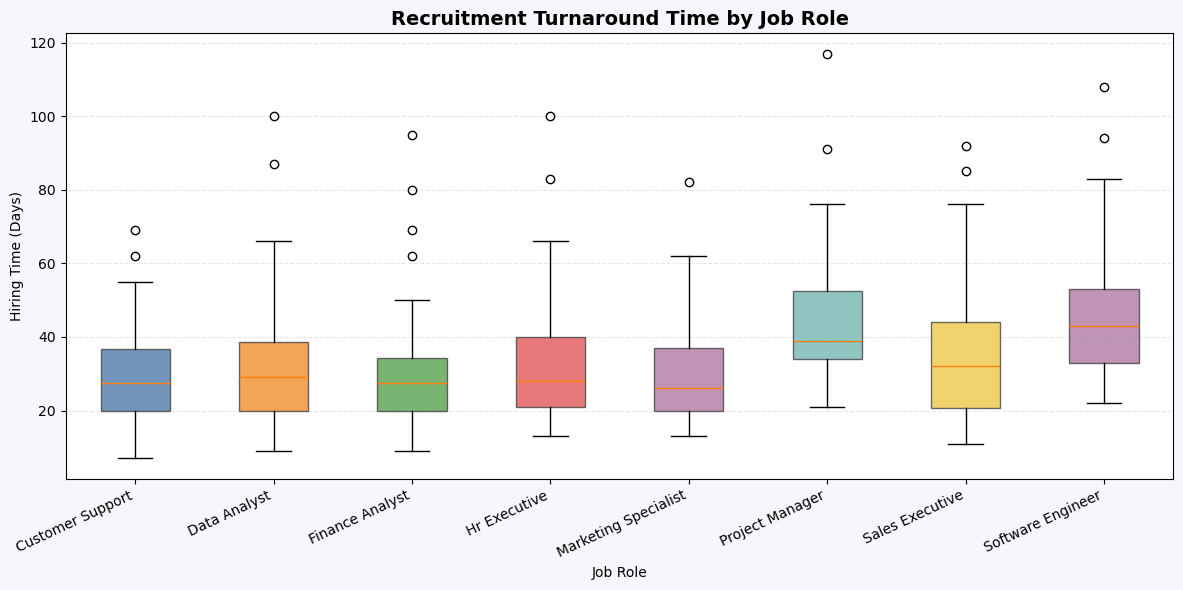

In [87]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6), facecolor="#F5F7FA")
ax.set_facecolor("#FFFFFF")

box = ax.boxplot(
    [group["Hiring Time"].dropna().values
     for _, group in df.groupby("Job Role")],
    patch_artist=True,
    labels=df.groupby("Job Role").groups.keys()
)

colors = ["#4E79A7", "#F28E2B", "#59A14F", "#E15759",
          "#B07AA1", "#76B7B2", "#EDC948", "#AF7AA1"]

for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
    patch.set_edgecolor("#444444")

plt.title("Recruitment Turnaround Time by Job Role",
          fontsize=14, fontweight="bold")
plt.xlabel("Job Role")
plt.ylabel("Hiring Time (Days)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 9) Find where the most candidates are being lost in the recruitment process
To do this, I looked at how many candidates were at each stage in the recruitment process.
It can be seen that:
Screening – 2053 candidates passed their screening, and 790 were rejected.
Interviews – 903 candidates were lost between screening and interviews.
Offer – 443 candidates were lost between interviews and offers.
Joining – 76 candidates were lost between offers and joining.
Offer Declined – 175 candidates declined their offer.

From this, you can see the biggest drop was between screening and interviews (903 candidates). This means that the company should focus more on this part of the process to improve its recruitment process.

10. Ways to improve the hiring process:

Screen correctly – Don’t call anyone who is not suitable for an interview.
Competitive salary – Offer them a competitive salary based on how skilled and experienced they are.
Friendly working environment – Provide a friendly and positive working environment.
Fast hiring process – Don’t take too long to complete the hiring process to avoid them losing interest.
Clearly describe the nature of the job – Clearly describe what the job involves when offering them a position.

In [81]:
df.columns

Index(['Candidate ID', 'Job Role', 'Application Date', 'Screening Status',
       'Interview Score', 'Interview Status', 'Offer Status', 'Joining Status',
       'Recruitment Source', 'Joining Date', 'Hiring Time'],
      dtype='object')

In [82]:
df["Screening Status"].value_counts()

Screening Status
Passed      2053
Rejected     790
Pending       81
Name: count, dtype: int64

In [83]:
df["Offer Status"].value_counts()

Offer Status
Not Offered    2001
Accepted        707
Declined        175
Pending          41
Name: count, dtype: int64